# Data Loading

In [1]:
import pandas as pd

data = pd.read_csv("predictions.csv", index_col = 0)
data.head()

,split_number,target_organism,curated_smiles,real_pIC50,pred_pIC50
2091,0,Staphylococcus aureus,COc1cc([C@H]2Oc3ccc(C4Oc5cc(O)cc(O)c5C(=O)C4O)...,4.178294,4.371202
1828,0,Staphylococcus aureus,CCOC(=O)Cn1nc(-n2cc(COc3cc(C(F)(F)F)[nH]c(=N)n...,5.134338,4.989416
1763,0,Staphylococcus aureus,N=c1[nH]cc(-c2ccc(NC(=O)c3cc4ccccc4[nH]3)cc2)[...,4.045757,4.017020
3772,0,Staphylococcus aureus,O=C(Nc1ccc(Sc2nc3ccccc3s2)c(Cl)c1)c1cccc(Br)c1O,6.000000,6.022084
4329,0,Staphylococcus aureus,Cn1cc(-c2nn3cc(-c4ccccc4)nc3s2)c2ccccc21,4.723538,5.056161


# Prediction Analysis

## Metrics

In [2]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
def analyze_results(data: pd.DataFrame):
    results = pd.DataFrame(columns=["R2", "MAE", "MSE", "RMSE"])
    for split in sorted(data.split_number.unique()):
        subdata = data[data.split_number.eq(split)]
        y_real = subdata.real_pIC50
        y_pred = subdata.pred_pIC50
        r2=r2_score(y_real, y_pred)
        mae= mean_absolute_error(y_real, y_pred)
        mse=mean_squared_error(y_real, y_pred)
        rmse=mse**0.5
        results.loc[f"Split {split}"] = [r2, mae, mse, rmse]

    results_mean, results_std = results.mean(), results.std()
    results.loc["mean"] = results_mean
    results.loc["std"] = results_std
    return results

analyze_results(data)

,R2,MAE,MSE,RMSE
Split 0,0.417347,0.358281,0.246567,0.496555
Split 1,0.338282,0.455156,0.365487,0.604555
Split 2,0.468592,0.359220,0.234853,0.484617
Split 3,0.428142,0.413991,0.323553,0.568817
Split 4,0.470313,0.360800,0.253950,0.503935
Split 5,0.401773,0.397980,0.316453,0.562542
Split 6,0.421773,0.361623,0.244138,0.494103
Split 7,0.358165,0.379329,0.277305,0.526597
Split 8,0.525350,0.371111,0.246115,0.496100
Split 9,0.528133,0.336217,0.223708,0.472978


# Graph

Text(0, 0.5, 'predicted pIC50')

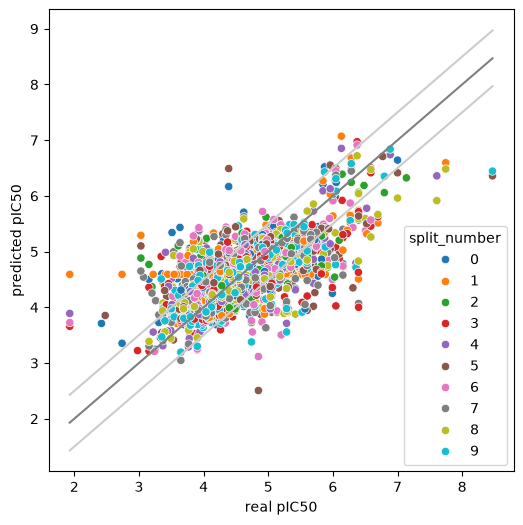

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

xmin = data.real_pIC50.min()
xmax = data.real_pIC50.max()

fig, ax = plt.subplots(figsize=(6,6))
sns.scatterplot(data, x='real_pIC50', y="pred_pIC50", hue="split_number", palette="tab10", legend="full")
sns.lineplot(x = [xmin,xmax], y=[xmin,xmax], color="gray", legend=None)
sns.lineplot(x = [xmin,xmax], y=[xmin-0.5, xmax-0.5], color="0.8", legend=None)
sns.lineplot(x = [xmin,xmax], y=[xmin+0.5, xmax+0.5], color="0.8", legend=None)
plt.xlabel('real pIC50')
plt.ylabel('predicted pIC50')

## RESULTS BY SPECIES

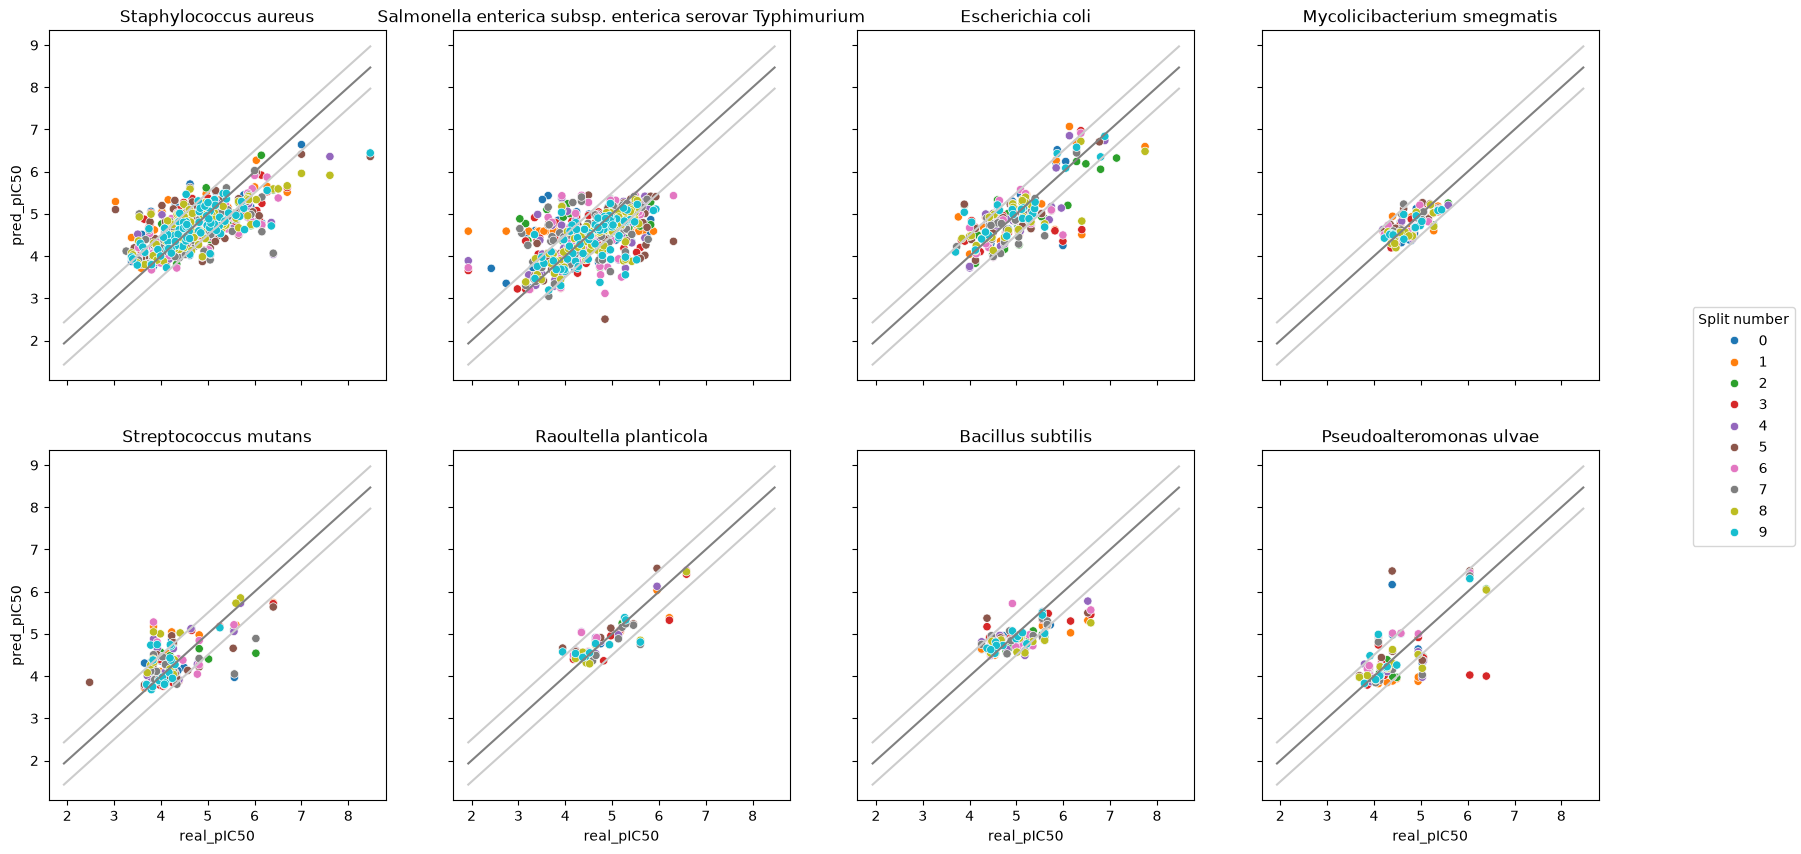

In [4]:
fig, axes = plt.subplots(2, 4, sharex="all", sharey="all", figsize = (20, 10))
for i, specie in enumerate(data.target_organism.unique()):
    ax = axes[i//4][i%4]
    subdata = data[data.target_organism.eq(specie)]
    legend = False if i else "full"
    sns.scatterplot(subdata, x='real_pIC50', y="pred_pIC50", hue="split_number", palette="tab10", legend=legend, ax=ax)
    sns.lineplot(x = [xmin,xmax], y=[xmin,xmax], color="gray", legend=None, ax=ax)
    sns.lineplot(x = [xmin,xmax], y=[xmin-0.5, xmax-0.5], color="0.8", legend=None, ax=ax)
    sns.lineplot(x = [xmin,xmax], y=[xmin+0.5, xmax+0.5], color="0.8", legend=None, ax=ax)
    ax.set_title(specie)
handles, labels = axes[0][0].get_legend_handles_labels()
axes[0][0].get_legend().remove()
fig.legend(handles, labels, loc='center right', title='Split number')

In [5]:
from collections import defaultdict

metrics = defaultdict(dict)

for specie in data.target_organism.unique():
    subdata = data[data.target_organism.eq(specie)]
    results = analyze_results(subdata)
    metrics["R2 mean"][specie] = results.loc["mean", "R2"]
    metrics["R2 std"][specie] = results.loc["std", "R2"]
    metrics["MAE mean"][specie] = results.loc["mean", "MAE"]
    metrics["MAE std"][specie] = results.loc["std", "MAE"]
    metrics["RMSE mean"][specie] = results.loc["mean", "RMSE"]
    metrics["RMSE std"][specie] = results.loc["std", "RMSE"]

metrics = pd.DataFrame(metrics)

metrics.round(3)

,R2 mean,R2 std,MAE mean,MAE std,RMSE mean,RMSE std
Staphylococcus aureus,0.479,0.076,0.385,0.040,0.515,0.055
Salmonella enterica subsp. enterica serovar Typhimurium,0.244,0.130,0.434,0.062,0.594,0.064
Escherichia coli,0.486,0.187,0.373,0.060,0.493,0.086
Mycolicibacterium smegmatis,0.341,0.306,0.217,0.031,0.258,0.024
Streptococcus mutans,0.179,0.377,0.385,0.069,0.506,0.091
Raoultella planticola,0.682,0.126,0.208,0.038,0.305,0.034
Bacillus subtilis,0.386,0.143,0.332,0.068,0.425,0.095
Pseudoalteromonas ulvae,-0.058,0.909,0.376,0.116,0.539,0.218


In [6]:
for specie in data.target_organism.unique():
    print(specie)
    subdata = data[data.target_organism.eq(specie)]
    y_real = subdata.real_pIC50
    y_pred = subdata.pred_pIC50
    print("r2_score", r2_score(y_real, y_pred))
    print("MAE", mean_absolute_error(y_real, y_pred))
    print("MSE", mean_squared_error(y_real, y_pred))
    print("RMSE", mean_squared_error(y_real, y_pred)**.5)
    print('..............')

Staphylococcus aureus
r2_score 0.4805136714690842
MAE 0.38517859503867213
MSE 0.2680438116473056
RMSE 0.5177294772825917
..............
Salmonella enterica subsp. enterica serovar Typhimurium
r2_score 0.2583560614908226
MAE 0.43349800672662364
MSE 0.35657696639512526
RMSE 0.5971406588025348
..............
Escherichia coli
r2_score 0.5301858831913578
MAE 0.3727485110273706
MSE 0.2492224327823795
RMSE 0.49922182722951874
..............
Mycolicibacterium smegmatis
r2_score 0.41655813634250627
MAE 0.21808272019636604
MSE 0.06726715256984818
RMSE 0.2593591189255704
..............
Streptococcus mutans
r2_score 0.3203620708116909
MAE 0.38057489986261
MSE 0.2562827514548762
RMSE 0.5062437668306408
..............
Raoultella planticola
r2_score 0.737908864902665
MAE 0.20809427613256162
MSE 0.09418708828894706
RMSE 0.3068991500296914
..............
Bacillus subtilis
r2_score 0.3926484679987625
MAE 0.3309470299567563
MSE 0.18660019762304358
RMSE 0.4319724500741264
..............
Pseudoalteromonas 